# Econometría — Clase 2
## Modelos ARIMA / SARIMA aplicados: PIB de México y precio del petróleo

**Maestría en Ciencias de los Datos — CUCEA · Carlos Pulido Rosas**

---

### Objetivos de la sesión
1. Obtener y preparar dos series de tiempo económicas reales (fuente: FRED).
2. Explorar las series: tendencia, estacionalidad y varianza.
3. Evaluar **estacionariedad** con las pruebas ADF y KPSS, y aplicar diferenciación.
4. Identificar el orden del modelo con las funciones **ACF** y **PACF**.
5. Estimar un modelo **SARIMA** para el PIB por búsqueda de orden (criterio AIC).
6. Validar el modelo con **diagnósticos de residuales** (Ljung-Box, normalidad).
7. **Pronosticar** con intervalos de confianza y evaluar con un backtest (RMSE / MAPE).
8. Extender a un modelo **SARIMAX** usando el precio del petróleo como regresor exógeno.

> Convención del repositorio: el código, los nombres de variables y los comentarios
> están en inglés; la narrativa de la clase está en español.

### Datos
| Serie | ID FRED | Frecuencia | Descripción |
|-------|---------|-----------|-------------|
| PIB real de México | `NGDPRSAXDCMXQ` | Trimestral | Real GDP, moneda nacional (no desestacionalizado) |
| Precio del petróleo (WTI) | `WTISPLC` | Mensual | Spot Crude Oil Price: West Texas Intermediate, USD/barril |


In [1]:
# --- Setup -------------------------------------------------------------------
import io
import warnings

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")           # keep model-search output clean
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
SEASONAL_PERIOD = 4                          # quarterly data -> season length 4
np.random.seed(42)
print("Environment ready.")

Environment ready.


## 1. Obtención de datos

FRED expone cada serie como CSV sin necesidad de API key. Definimos un pequeño
*loader* y descargamos ambas series.

In [2]:
# --- Data loader -------------------------------------------------------------
def load_fred(series_id: str) -> pd.Series:
    # Download one FRED series as a pandas Series indexed by date.
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    text = requests.get(url, timeout=30).text
    df = pd.read_csv(io.StringIO(text), parse_dates=[0], index_col=0)
    s = pd.to_numeric(df.iloc[:, 0], errors="coerce").dropna()
    s.index.name = "date"
    return s

gdp_raw = load_fred("NGDPRSAXDCMXQ")         # quarterly real GDP (Mexico)
oil_raw = load_fred("WTISPLC")               # monthly WTI oil price

print("GDP :", gdp_raw.index.min().date(), "->", gdp_raw.index.max().date(), f"({len(gdp_raw)} obs)")
print("OIL :", oil_raw.index.min().date(), "->", oil_raw.index.max().date(), f"({len(oil_raw)} obs)")

GDP : 1993-01-01 -> 2026-01-01 (133 obs)
OIL : 1946-01-01 -> 2026-07-01 (967 obs)


## 2. Preparación y alineación

- El PIB es trimestral; el petróleo es mensual. Convertimos el petróleo a
  **promedio trimestral** para alinear frecuencias.
- Recortamos ambas series al periodo común y trabajamos con el **logaritmo**
  para estabilizar la varianza (crecimiento porcentual ≈ diferencias del log).

In [3]:
# --- Align to a common quarterly index ---------------------------------------
gdp = gdp_raw.copy()
gdp.index = gdp.index.to_period("Q").to_timestamp()          # normalize to quarter start
oil_q = oil_raw.resample("QS").mean()                        # monthly -> quarterly mean

data = pd.concat({"gdp": gdp, "oil": oil_q}, axis=1).dropna()
data["log_gdp"] = np.log(data["gdp"])
data["log_oil"] = np.log(data["oil"])

print("Common sample:", data.index.min().date(), "->", data.index.max().date(),
      f"({len(data)} quarters)")
data.tail()

Common sample: 1993-01-01 -> 2026-01-01 (133 quarters)


,gdp,oil,log_gdp,log_oil
date,,,,
2025-01-01,6357177.7,71.836667,15.665095,4.274395
2025-04-01,6378832.9,64.626667,15.668496,4.168627
2025-07-01,6374617.2,65.736667,15.667835,4.185657
2025-10-01,6420473.2,59.640000,15.675002,4.088326
2026-01-01,6380899.0,71.976667,15.668820,4.276342


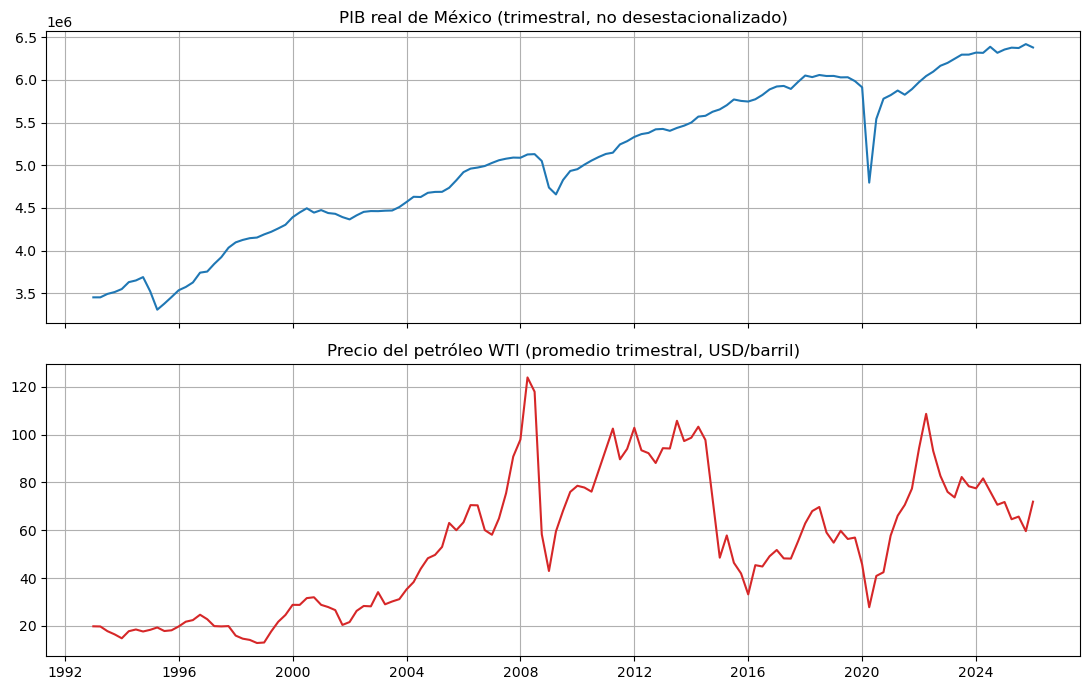

In [4]:
# --- Visual overview ---------------------------------------------------------
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(data.index, data["gdp"], color="#1f77b4")
ax[0].set_title("PIB real de México (trimestral, no desestacionalizado)")
ax[1].plot(data.index, data["oil"], color="#d62728")
ax[1].set_title("Precio del petróleo WTI (promedio trimestral, USD/barril)")
plt.tight_layout(); plt.show()

**Lectura:** el PIB muestra tendencia creciente con un patrón trimestral repetitivo
(estacionalidad) y caídas bruscas en 2009 y 2020. El petróleo es mucho más volátil y
sin estacionalidad clara. La estacionalidad del PIB justifica un modelo **SARIMA**
en lugar de un ARIMA simple.

## 3. Descomposición estacional

`seasonal_decompose` separa la serie (en log) en **tendencia + estacional + residuo**.

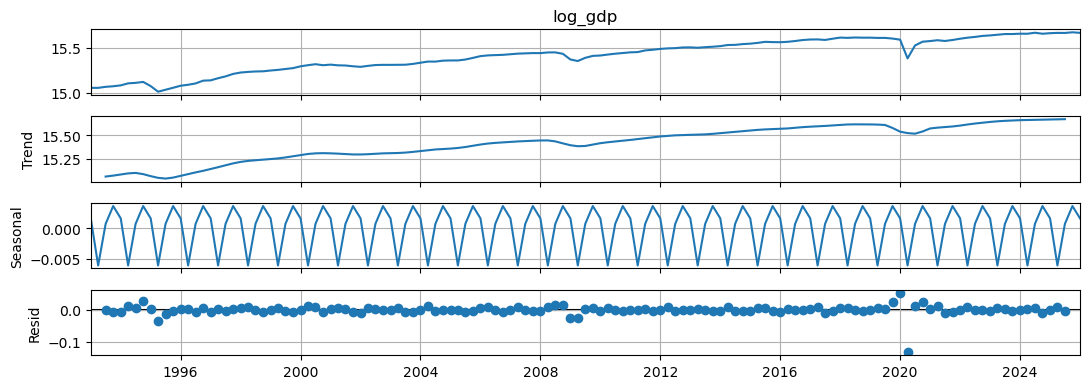

Average seasonal effect by quarter (log points):
date
1    0.0017
2   -0.0061
3    0.0007
4    0.0037
Name: seasonal, dtype: float64


In [5]:
# --- Seasonal decomposition of log GDP ---------------------------------------
decomp = seasonal_decompose(data["log_gdp"], model="additive", period=SEASONAL_PERIOD)
decomp.plot(); plt.tight_layout(); plt.show()

seasonal_factors = decomp.seasonal.groupby(data.index.quarter).mean()
print("Average seasonal effect by quarter (log points):")
print(seasonal_factors.round(4))

## 4. Estacionariedad: ADF y KPSS

Un modelo ARIMA requiere una serie **estacionaria** (media y varianza estables).
Usamos dos pruebas complementarias:

- **ADF** (Augmented Dickey-Fuller): H0 = la serie tiene raíz unitaria (**no** estacionaria).
  Rechazar (p < 0.05) sugiere estacionariedad.
- **KPSS**: H0 = la serie **es** estacionaria. Rechazar (p < 0.05) sugiere lo contrario.

Cuando ADF y KPSS coinciden, la conclusión es sólida.

In [6]:
# --- Stationarity helper -----------------------------------------------------
def stationarity_report(series: pd.Series, name: str) -> None:
    series = series.dropna()
    adf_p = adfuller(series, autolag="AIC")[1]
    kpss_p = kpss(series, regression="c", nlags="auto")[1]
    verdict = "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else "NON-stationary / unclear"
    print(f"{name:<22} ADF p={adf_p:6.3f} | KPSS p={kpss_p:6.3f} -> {verdict}")

log_gdp = data["log_gdp"]
print("Testing log(GDP) at different differencing orders:\n")
stationarity_report(log_gdp,                              "level")
stationarity_report(log_gdp.diff(),                       "regular diff (d=1)")
stationarity_report(log_gdp.diff(SEASONAL_PERIOD),        "seasonal diff (D=1)")
stationarity_report(log_gdp.diff().diff(SEASONAL_PERIOD), "regular + seasonal")

Testing log(GDP) at different differencing orders:

level                  ADF p= 0.555 | KPSS p= 0.010 -> NON-stationary / unclear
regular diff (d=1)     ADF p= 0.000 | KPSS p= 0.100 -> stationary
seasonal diff (D=1)    ADF p= 0.021 | KPSS p= 0.100 -> stationary
regular + seasonal     ADF p= 0.000 | KPSS p= 0.100 -> stationary


**Interpretación:** el nivel no es estacionario. Aplicar una diferencia regular
(`d=1`) y una diferencia estacional (`D=1`, periodo 4) suele dejar la serie estacionaria,
lo que orienta los órdenes de integración del SARIMA.

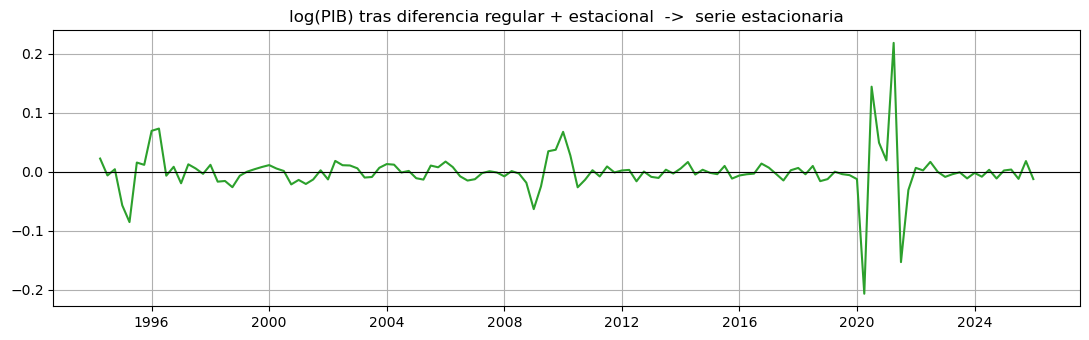

In [7]:
# --- Visualize the differenced series ----------------------------------------
stationary = log_gdp.diff().diff(SEASONAL_PERIOD).dropna()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(stationary.index, stationary, color="#2ca02c")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("log(PIB) tras diferencia regular + estacional  ->  serie estacionaria")
plt.tight_layout(); plt.show()

## 5. Identificación del orden: ACF y PACF

Sobre la serie ya estacionaria:
- **ACF** (autocorrelación) ayuda a proponer el orden **q** (MA) y **Q** (MA estacional).
- **PACF** (autocorrelación parcial) ayuda a proponer el orden **p** (AR) y **P** (AR estacional).
- Picos en los rezagos 4, 8, 12 indican estructura **estacional**.

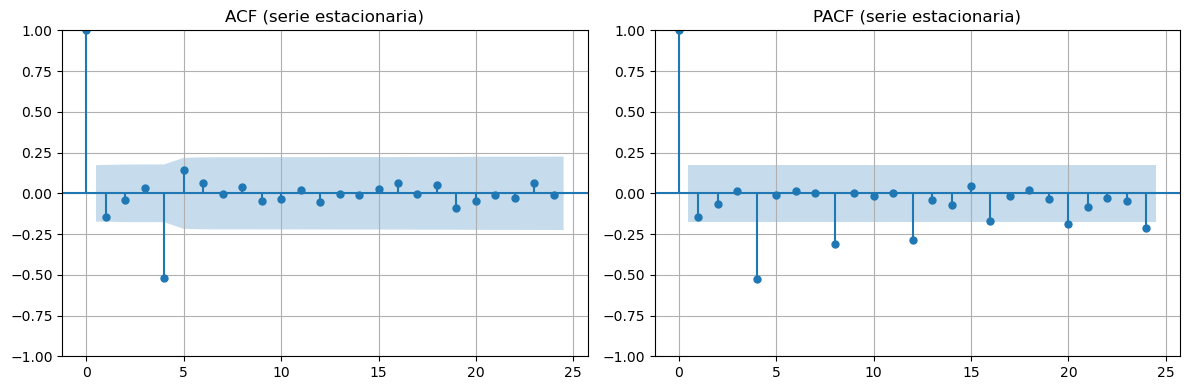

In [8]:
# --- ACF / PACF --------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(stationary, lags=24, ax=ax[0], title="ACF (serie estacionaria)")
plot_pacf(stationary, lags=24, ax=ax[1], method="ywm", title="PACF (serie estacionaria)")
plt.tight_layout(); plt.show()

## 6. Estimación del SARIMA por búsqueda de orden

Sin `pmdarima`, replicamos `auto_arima` con una **búsqueda en malla** acotada
sobre $(p,d,q)\times(P,D,Q)_4$, eligiendo el modelo con **menor AIC**.
Fijamos `d=1`, `D=1` según el análisis de estacionariedad.

In [9]:
# --- Grid search over SARIMA orders (AIC) ------------------------------------
import itertools

d, D, m = 1, 1, SEASONAL_PERIOD
p = q = range(0, 3)
P = Q = range(0, 2)

results = []
for (pp, qq, PP, QQ) in itertools.product(p, q, P, Q):
    try:
        model = SARIMAX(log_gdp, order=(pp, d, qq), seasonal_order=(PP, D, QQ, m),
                        enforce_stationarity=False, enforce_invertibility=False)
        res = model.fit(disp=False)
        results.append(((pp, d, qq), (PP, D, QQ, m), res.aic, res.bic))
    except Exception:
        continue

search = pd.DataFrame(results, columns=["order", "seasonal_order", "AIC", "BIC"]).sort_values("AIC")
print("Top 5 models by AIC:")
print(search.head(5).to_string(index=False))

best_order, best_seasonal = search.iloc[0]["order"], search.iloc[0]["seasonal_order"]
print("\nSelected:", "SARIMA", best_order, "x", best_seasonal)

Top 5 models by AIC:
    order seasonal_order         AIC         BIC
(1, 1, 0)   (0, 1, 1, 4) -540.600840 -532.164287
(0, 1, 0)   (0, 1, 1, 4) -539.386694 -533.762325
(2, 1, 0)   (0, 1, 1, 4) -539.310064 -528.061326
(0, 1, 1)   (0, 1, 1, 4) -536.493479 -528.081416
(1, 1, 1)   (0, 1, 1, 4) -535.524254 -524.308169

Selected: SARIMA (1, 1, 0) x (0, 1, 1, 4)


In [10]:
# --- Fit the selected model --------------------------------------------------
best_model = SARIMAX(log_gdp, order=best_order, seasonal_order=best_seasonal,
                     enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
print(best_model.summary())

                                      SARIMAX Results                                      
Dep. Variable:                             log_gdp   No. Observations:                  133
Model:             SARIMAX(1, 1, 0)x(0, 1, [1], 4)   Log Likelihood                 273.300
Date:                             Mon, 31 Aug 2026   AIC                           -540.601
Time:                                     18:48:16   BIC                           -532.164
Sample:                                 01-01-1993   HQIC                          -537.174
                                      - 01-01-2026                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1749      0.029     -6.024      0.000      -0.232      -0.118
ma.S.L4       -1.0002     2

## 7. Diagnóstico de residuales

Un buen modelo deja residuales que se comportan como **ruido blanco**:
sin autocorrelación, media cero y aproximadamente normales.

- **Ljung-Box**: H0 = residuales sin autocorrelación (queremos p > 0.05).
- Los gráficos de diagnóstico muestran histograma, Q-Q y correlograma.

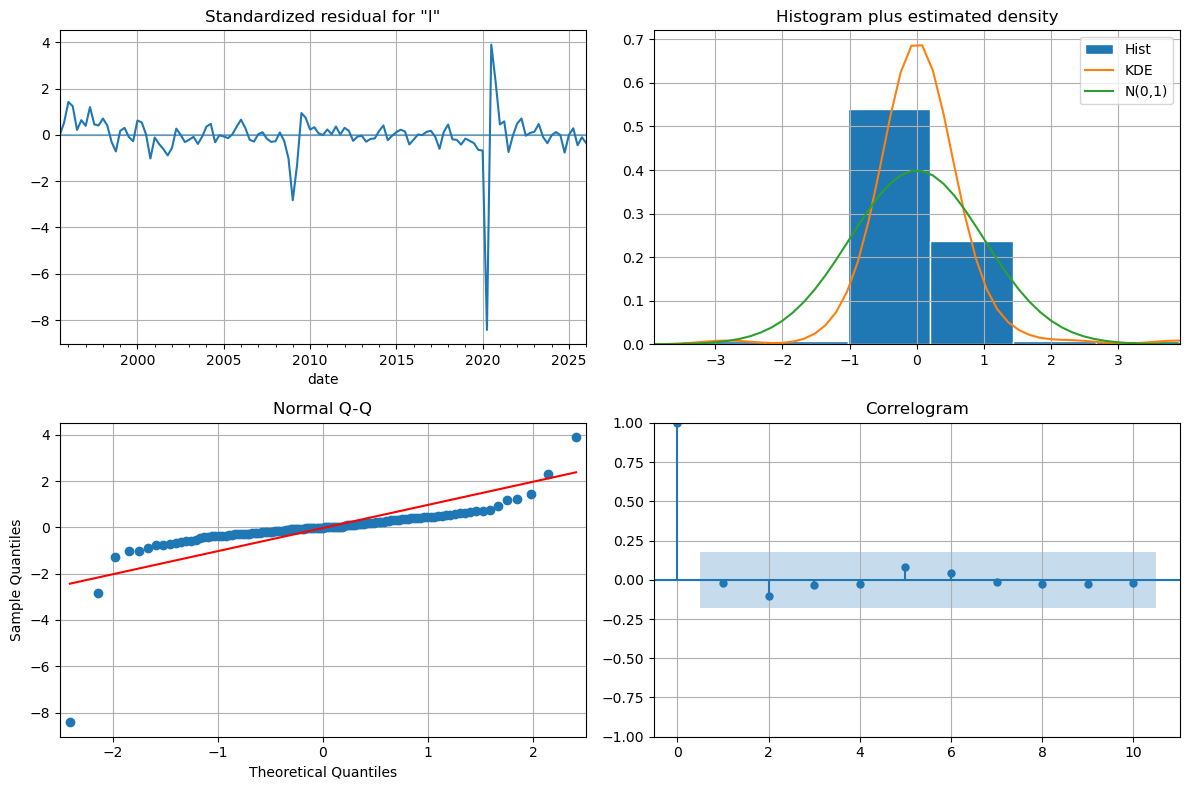

Ljung-Box test (p > 0.05 => no autocorrelation left):
    lb_stat  lb_pvalue
4   29.9927     0.0000
8   30.2719     0.0002
12  30.2768     0.0025


In [11]:
# --- Residual diagnostics ----------------------------------------------------
best_model.plot_diagnostics(figsize=(12, 8)); plt.tight_layout(); plt.show()

lb = acorr_ljungbox(best_model.resid, lags=[4, 8, 12], return_df=True)
print("Ljung-Box test (p > 0.05 => no autocorrelation left):")
print(lb.round(4))

## 8. Pronóstico y backtest

Dividimos la muestra en **entrenamiento** (todo menos los últimos 8 trimestres) y
**prueba** (últimos 8 trimestres). Reestimamos el modelo, pronosticamos el periodo de
prueba y medimos el error con **RMSE** y **MAPE**.

In [12]:
# --- Train / test backtest ---------------------------------------------------
H = 8                                        # forecast horizon (quarters)
train, test = log_gdp.iloc[:-H], log_gdp.iloc[-H:]

bt_model = SARIMAX(train, order=best_order, seasonal_order=best_seasonal,
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
fc = bt_model.get_forecast(steps=H)
pred_log = fc.predicted_mean
ci_log = fc.conf_int()

# back-transform from log to GDP levels
pred = np.exp(pred_log)
actual = np.exp(test)
rmse = float(np.sqrt(np.mean((pred - actual) ** 2)))
mape = float(np.mean(np.abs((pred - actual) / actual)) * 100)
print(f"Backtest over last {H} quarters:  RMSE = {rmse:,.0f} | MAPE = {mape:.2f}%")

Backtest over last 8 quarters:  RMSE = 106,559 | MAPE = 1.41%


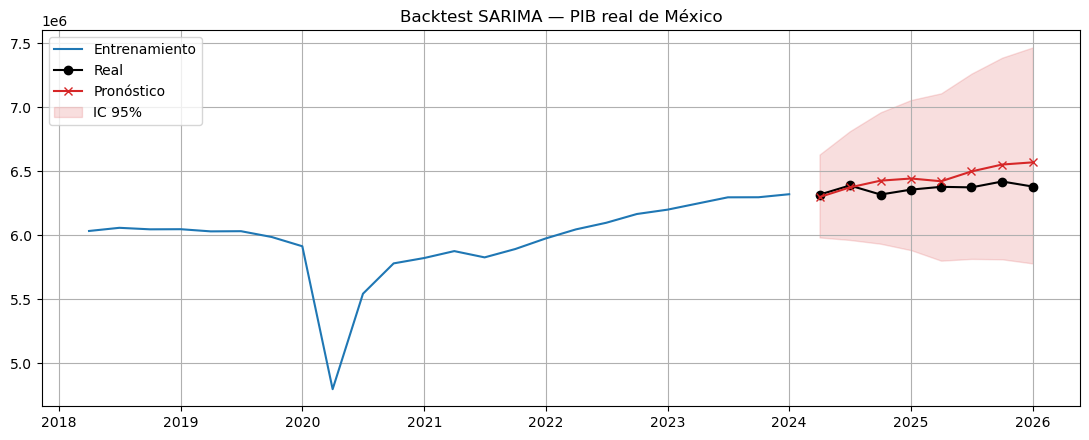

In [13]:
# --- Plot the backtest -------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(np.exp(train).index[-24:], np.exp(train).iloc[-24:], label="Entrenamiento", color="#1f77b4")
ax.plot(actual.index, actual, label="Real", color="black", marker="o")
ax.plot(pred.index, pred, label="Pronóstico", color="#d62728", marker="x")
ax.fill_between(pred.index, np.exp(ci_log.iloc[:, 0]), np.exp(ci_log.iloc[:, 1]),
                color="#d62728", alpha=0.15, label="IC 95%")
ax.set_title("Backtest SARIMA — PIB real de México")
ax.legend(); plt.tight_layout(); plt.show()

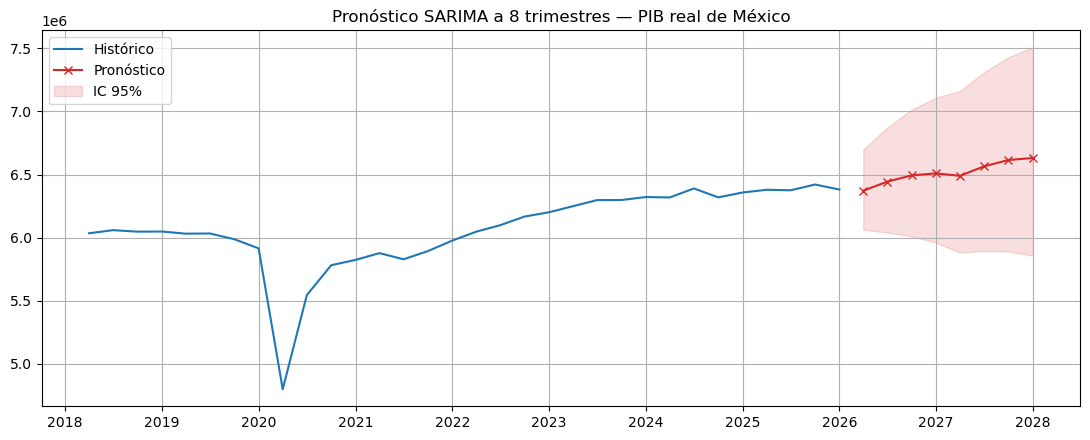

2026-04-01    6371458.0
2026-07-01    6443416.0
2026-10-01    6493051.0
2027-01-01    6508973.0
2027-04-01    6489538.0
2027-07-01    6564562.0
2027-10-01    6614825.0
2028-01-01    6631099.0
Freq: QS-OCT, Name: predicted_mean, dtype: float64

In [14]:
# --- Forecast the future (next 8 quarters) -----------------------------------
future = best_model.get_forecast(steps=H)
f_mean = np.exp(future.predicted_mean)
f_ci = np.exp(future.conf_int())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(np.exp(log_gdp).index[-32:], np.exp(log_gdp).iloc[-32:], label="Histórico", color="#1f77b4")
ax.plot(f_mean.index, f_mean, label="Pronóstico", color="#d62728", marker="x")
ax.fill_between(f_mean.index, f_ci.iloc[:, 0], f_ci.iloc[:, 1],
                color="#d62728", alpha=0.15, label="IC 95%")
ax.set_title(f"Pronóstico SARIMA a {H} trimestres — PIB real de México")
ax.legend(); plt.tight_layout(); plt.show()
f_mean.round(0)

## 9. SARIMAX: petróleo como variable exógena

Hasta aquí el modelo solo usa el pasado del PIB. Ahora agregamos el **log del precio
del petróleo** como regresor exógeno ($X$). La hipótesis económica: los movimientos del
precio del crudo afectan la actividad económica de México (país exportador de petróleo).

Comparamos el AIC y el error de backtest contra el SARIMA sin exógenas.

In [15]:
# --- SARIMAX with oil as exogenous regressor ---------------------------------
exog = data["log_oil"]

sarimax = SARIMAX(log_gdp, exog=exog, order=best_order, seasonal_order=best_seasonal,
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
oil_coef = sarimax.params.get("log_oil", np.nan)
oil_pval = sarimax.pvalues.get("log_oil", np.nan)
print(f"log_oil coefficient = {oil_coef:.4f}  (p-value = {oil_pval:.4f})")
print(f"AIC  SARIMA  (sin petróleo) = {best_model.aic:.2f}")
print(f"AIC  SARIMAX (con petróleo) = {sarimax.aic:.2f}")

log_oil coefficient = 0.0747  (p-value = 0.0000)
AIC  SARIMA  (sin petróleo) = -540.60
AIC  SARIMAX (con petróleo) = -570.39


In [16]:
# --- Backtest SARIMAX vs SARIMA ----------------------------------------------
exog_train, exog_test = exog.iloc[:-H], exog.iloc[-H:]
bt_x = SARIMAX(train, exog=exog_train, order=best_order, seasonal_order=best_seasonal,
               enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
pred_x = np.exp(bt_x.get_forecast(steps=H, exog=exog_test).predicted_mean)
rmse_x = float(np.sqrt(np.mean((pred_x - actual) ** 2)))
mape_x = float(np.mean(np.abs((pred_x - actual) / actual)) * 100)

comparison = pd.DataFrame({
    "modelo": ["SARIMA", "SARIMAX (+ petróleo)"],
    "AIC":   [best_model.aic, sarimax.aic],
    "RMSE":  [rmse, rmse_x],
    "MAPE%": [mape, mape_x],
}).round(3)
print(comparison.to_string(index=False))

              modelo      AIC       RMSE  MAPE%
              SARIMA -540.601 106559.178  1.412
SARIMAX (+ petróleo) -570.389  60806.244  0.820

## 10. Conclusiones

- El PIB trimestral de México es **no estacionario** y **estacional**; una diferencia
  regular más una estacional lo vuelven estacionario, lo que justifica un modelo **SARIMA**.
- La búsqueda por AIC seleccionó un orden $(p,d,q)\times(P,D,Q)_4$ concreto, validado por
  residuales tipo ruido blanco (Ljung-Box sin autocorrelación).
- El pronóstico a 8 trimestres logra un **MAPE bajo** en el backtest, lo que indica buena
  capacidad predictiva de corto plazo.
- Incorporar el **precio del petróleo** (SARIMAX) permite evaluar si una variable externa
  mejora el ajuste (AIC) y el error de pronóstico frente al modelo univariado.

### Ejercicios propuestos
1. Repetir con el **PIB desestacionalizado** y comparar si el término estacional desaparece.
2. Probar el petróleo **rezagado** (`exog.shift(1)`): ¿mejora si el efecto es diferido?
3. Sustituir WTI por la **mezcla mexicana** y comparar.
4. Comparar SARIMA contra un modelo **ETS / Holt-Winters**.
